# CodeT5-Architecture SFT (Own Pretrained) -- Colab


## Cell 1 -- Imports & Device

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, random, functools
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))

%pip install -q transformers

from src.model_config import ModelConfig, count_parameters
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.data_loaders import SFTDataset, collate_sft
from src.training import make_scheduler

import torch
from torch.utils.data import DataLoader
from transformers import T5Config, T5ForConditionalGeneration
import numpy as np

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")

Mounted at /content/drive
[training.py] SRC_VERSION = role-aware-pgen-v1-restored
[calibration_training.py] SRC_VERSION = calibration-selfrollout-v2-batched
[confidence_head_training.py] SRC_VERSION = confidence-head-v1
Device: cuda  |  PyTorch: 2.11.0+cu128


## Cell 1b -- Weights & Biases

Same wandb account as the rest of the project. Project name
`codet5-own-sft` keeps this run separate from the TLM ladder's
`tlm-{s,m}-sft` dashboards and from the official-CodeT5-weights run
(`codet5-official-sft`, in the sibling notebook).

In [ ]:

%pip install -q wandb
import wandb
wandb.login(key="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")

True

## Cell 2 -- Paths & Run Config

**Do NOT point this at the raw `codet5_arch_pretrain` checkpoint** -- the
whole point of this notebook is to build on top of bridging's task-token
conditioning, same hard rule as the TLM ladder's own SFT notebook.
`CODET5_BRIDGING_CKPT_DIR` must contain the output of
the CodeT5 (own) bridging step (run `codet5_own_bridging`) -- verify it
actually has `codet5_own_bridging_epoch_*_val*.pt` files before running the
next cells.


In [ ]:
FINETUNE_DIR    = DRIVE_ROOT / "data" / "finetune_data"
FULL_TRAIN_PATH = FINETUNE_DIR / "supervised_finetuning_generated.jsonl"  # full 75k, train_domains

TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")

CODET5_BRIDGING_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / "codet5_small_bridging"

# -- RUN CONFIG -- set every time --
RUN_NAME = "codet5_small_sft" 
RUN_MODE = "fresh"   # "fresh" or "resume"
assert RUN_MODE in ("fresh", "resume"), f"RUN_MODE must be 'fresh' or 'resume', got {RUN_MODE!r}"

SFT_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME
SFT_CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"checkpoints -> {SFT_CKPT_DIR}")


checkpoints -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_small_sft


## Cell 2b -- Same-domain train/val split


In [8]:
from collections import defaultdict

SFT_TRAIN_PATH = FINETUNE_DIR / "sft_train_domain.jsonl"
SFT_VAL_PATH   = FINETUNE_DIR / "sft_val_domain.jsonl"

_VAL_FRAC   = 0.05
_SPLIT_SEED = 2025

_by_type = defaultdict(list)
with open(FULL_TRAIN_PATH, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        rec = json.loads(line)
        _by_type[rec["type"]].append(rec)

_rng = random.Random(_SPLIT_SEED)
_train_recs, _val_recs = [], []
for ttype, recs in sorted(_by_type.items()):
    recs = recs[:]
    _rng.shuffle(recs)
    n_val = round(len(recs) * _VAL_FRAC)
    _val_recs.extend(recs[:n_val])
    _train_recs.extend(recs[n_val:])
    print(f"  {ttype:18} total {len(recs):6,}  ->  train {len(recs) - n_val:6,}  val {n_val:4,}")

_rng.shuffle(_train_recs)
_rng.shuffle(_val_recs)

with open(SFT_TRAIN_PATH, "w", encoding="utf-8") as f:
    for rec in _train_recs:
        f.write(json.dumps(rec) + "\n")
with open(SFT_VAL_PATH, "w", encoding="utf-8") as f:
    for rec in _val_recs:
        f.write(json.dumps(rec) + "\n")
print(f"wrote {len(_train_recs):,} train / {len(_val_recs):,} val -> {SFT_TRAIN_PATH.name}, {SFT_VAL_PATH.name}")

  deduplicate        total 15,000  ->  train 14,250  val  750
  extract_method     total 15,000  ->  train 14,250  val  750
  remove_dead_code   total 15,000  ->  train 14,250  val  750
  rename             total 15,000  ->  train 14,250  val  750
  simplify           total 15,000  ->  train 14,250  val  750
wrote 71,250 train / 3,750 val -> sft_train_domain.jsonl, sft_val_domain.jsonl


## Cell 3 -- Tokenizer, CodeT5-Small Architecture & Bridging Checkpoint


In [11]:
tlm_config = ModelConfig()   # only used for special_token_ids / vocab_size
PAD_ID = tlm_config.special_token_ids["pad"]
BOS_ID = tlm_config.special_token_ids["bos"]
EOS_ID = tlm_config.special_token_ids["eos"]

tokenizer = TLM_Tokenizer(vocab_size=tlm_config.vocab_size)
tokenizer.load(TOKENIZER_PATH)
VOCAB_SIZE = tokenizer.tokenizer.get_vocab_size()
print(f"Tokenizer loaded from {TOKENIZER_PATH}  |  vocab_size={VOCAB_SIZE}  pad={PAD_ID}  bos={BOS_ID}  eos={EOS_ID}")

t5_config = T5Config.from_pretrained("Salesforce/codet5-small")
t5_config.vocab_size = VOCAB_SIZE
t5_config.pad_token_id = PAD_ID
t5_config.eos_token_id = EOS_ID
t5_config.decoder_start_token_id = BOS_ID
t5_config.d_model = 256
t5_config.d_ff = 1024
t5_config.num_layers = 4
t5_config.num_decoder_layers = 4
t5_config.num_heads = 4
t5_config.d_kv=64

model = T5ForConditionalGeneration(t5_config).to(device)

_ckpts = sorted(CODET5_BRIDGING_CKPT_DIR.glob("codet5_small_bridging_epoch_*_val*.pt"))
assert _ckpts, (f"No checkpoints found in {CODET5_BRIDGING_CKPT_DIR} -- run "
                 "the CodeT5 (own) bridging step first (do NOT fall back to the raw "
                 "codet5_arch_pretrain checkpoint here).")

def _val_loss_from_name(p):
    m = re.search(r"val([0-9.]+)\.pt$", p.name)
    return float(m.group(1)) if m else float("inf")

BRIDGING_CKPT_PATH = min(_ckpts, key=_val_loss_from_name)
print(f"Found {len(_ckpts)} checkpoint(s) in {CODET5_BRIDGING_CKPT_DIR}")
print(f"Using: {BRIDGING_CKPT_PATH.name}")

_state = torch.load(BRIDGING_CKPT_PATH, map_location=device)
model.load_state_dict(_state["model"])
print(f"Loaded bridging checkpoint: epoch {_state.get('epoch')}  val_loss {_state.get('val_loss')}")

n_params = sum(p.numel() for p in model.parameters())
print(f"Model params: {n_params/1e6:.3f}M")

# Gradient checkpointing -- same OOM mitigation as the pretrain/bridging notebooks; harmless
# to leave on for SFT too given this model's the same size. use_cache re-enabled after
# training for generation (Cell 8 below flips it back on before calling .generate()).
model.gradient_checkpointing_enable()
model.config.use_cache = False


Tokenizer loaded from /content/drive/MyDrive/TLM_V03/src/tokenizer/tokenizer_tlm_small.json  |  vocab_size=10000  pad=0  bos=2  eos=3
Found 4 checkpoint(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_small_bridging
Using: codet5_small_bridging_epoch_4_val0.1224.pt
Loaded bridging checkpoint: epoch 4  val_loss 0.12239330135664697
Model params: 9.906M


## Cell 4 -- SFT Datasets & DataLoaders

In [ ]:
train_ds = SFTDataset(SFT_TRAIN_PATH, tokenizer, tlm_config)
val_ds   = SFTDataset(SFT_VAL_PATH, tokenizer, tlm_config)
print(f"train: {len(train_ds):,} kept, {train_ds.dropped} dropped {train_ds.dropped_by_type}")
print(f"val:   {len(val_ds):,} kept, {val_ds.dropped} dropped {val_ds.dropped_by_type}")
print(f"train kept by type: {train_ds.kept_by_type}")
print(f"val kept by type:   {val_ds.kept_by_type}")

BATCH_SIZE       = 16
GRAD_ACCUM_STEPS = 2
EFFECTIVE_BATCH_SIZE = BATCH_SIZE * GRAD_ACCUM_STEPS
NUM_WORKERS = os.cpu_count() if torch.cuda.is_available() else 0
_PIN        = torch.cuda.is_available()
_collate    = lambda b: collate_sft(b, PAD_ID)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
print(f"train batches: {len(train_loader)}  |  val batches: {len(val_loader)}  |  "
      f"effective batch size: {EFFECTIVE_BATCH_SIZE}  |  device: {device}")

train: 71,192 kept, 58 dropped {'deduplicate': 57, 'rename': 1}
val:   3,747 kept, 3 dropped {'deduplicate': 3}
train kept by type: {'remove_dead_code': 14250, 'simplify': 14250, 'deduplicate': 14193, 'rename': 14249, 'extract_method': 14250}
val kept by type:   {'remove_dead_code': 750, 'rename': 750, 'simplify': 750, 'extract_method': 750, 'deduplicate': 747}
train batches: 4450  |  val batches: 235  |  effective batch size: 32  |  device: cuda


## Cell 5 -- HF Forward/Loss Step & Optimizer


In [13]:
def hf_step_batch(model, batch, pad_id, device, amp_dtype=None):
    enc_ids  = batch["enc_ids"].to(device)
    enc_attn = batch["enc_attn"].to(device)
    dec_ids  = batch["dec_ids"].to(device)

    labels = dec_ids[:, 1:].clone()
    labels[labels == pad_id] = -100

    if amp_dtype is not None:
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            out = model(input_ids=enc_ids, attention_mask=enc_attn, labels=labels)
    else:
        out = model(input_ids=enc_ids, attention_mask=enc_attn, labels=labels)
    return out.loss


@torch.no_grad()
def hf_validate(model, loader, pad_id, device, amp_dtype=None, log_every=200):
    model.eval()
    total_loss, n_batches = 0.0, 0
    for i, batch in enumerate(loader):
        loss = hf_step_batch(model, batch, pad_id, device, amp_dtype=amp_dtype)
        total_loss += float(loss.detach())
        n_batches += 1
        if (i + 1) % log_every == 0:
            print(f"    [val] {i+1}/{len(loader)}", flush=True)
    return total_loss / max(n_batches, 1)


def hf_run_epoch(model, loader, optimizer, scheduler, pad_id, device,
                 grad_accum_steps=1, amp_dtype=None, grad_clip=1.0, log_every=200):
    model.train()
    total_loss, n_micro = 0.0, 0
    optimizer.zero_grad(set_to_none=True)
    for i, batch in enumerate(loader):
        loss = hf_step_batch(model, batch, pad_id, device, amp_dtype=amp_dtype)
        (loss / grad_accum_steps).backward()
        total_loss += float(loss.detach())
        n_micro += 1

        if n_micro % grad_accum_steps == 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        if (i + 1) % log_every == 0:
            print(f"    step {i+1}/{len(loader)}  loss={total_loss/n_micro:.4f}  "
                  f"lr={scheduler.get_last_lr()[0]:.2e}", flush=True)

    if n_micro % grad_accum_steps != 0:
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)

    return total_loss / max(n_micro, 1)


EPOCHS       = 25
LR           = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
GRAD_CLIP    = 1.0
PATIENCE     = 3
USE_AMP      = False   # T5 + fp16 -> NaN risk; leave off unless still OOMing after batch/accum tuning
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_available()
                               and torch.cuda.is_bf16_supported()) else None

steps_per_epoch  = len(train_loader) // GRAD_ACCUM_STEPS
total_steps      = steps_per_epoch * EPOCHS
warmup_steps     = int(total_steps * WARMUP_RATIO)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, warmup_steps, total_steps)

print(f"epochs={EPOCHS}  steps/epoch={steps_per_epoch}  total={total_steps}  "
      f"warmup={warmup_steps}  lr={LR}  effective_batch={EFFECTIVE_BATCH_SIZE}")

epochs=25  steps/epoch=2225  total=55625  warmup=2781  lr=3e-05  effective_batch=32


## Cell 6 -- Train Loop (resumable)


In [14]:
RESUME_PATH = SFT_CKPT_DIR / "last.pt"
RUN_ID_PATH = SFT_CKPT_DIR / "wandb_run_id.txt"

best_val       = float("inf")
best_ckpt_path = None
bad_epochs     = 0
history        = []
start_epoch    = 1

if RUN_MODE == "resume":
    assert RESUME_PATH.exists(), (
        f"RUN_MODE='resume' but no last.pt found at {RESUME_PATH} -- "
        f"check RUN_NAME={RUN_NAME!r} is correct, or set RUN_MODE='fresh' to start a new run.")
    print(f"Resuming {RUN_NAME!r} from {RESUME_PATH}")
    _ckpt = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(_ckpt["model"])
    optimizer.load_state_dict(_ckpt["optimizer"])
    scheduler.load_state_dict(_ckpt["scheduler"])
    start_epoch    = _ckpt["epoch"] + 1
    best_val       = _ckpt["best_val"]
    bad_epochs     = _ckpt["bad_epochs"]
    best_ckpt_path = Path(_ckpt["best_ckpt_path"]) if _ckpt.get("best_ckpt_path") else None
    history        = _ckpt["history"]
    wandb_run_id   = _ckpt.get("wandb_run_id") or RUN_ID_PATH.read_text().strip()
    print(f"  resuming at epoch {start_epoch}  |  best_val so far {best_val:.4f}  |  "
          f"bad_epochs {bad_epochs}/{PATIENCE}")
else:
    assert not RESUME_PATH.exists(), (
        f"RUN_MODE='fresh' but {RESUME_PATH} already exists (a previous run under "
        f"RUN_NAME={RUN_NAME!r} is in progress) -- set RUN_MODE='resume' to continue it, "
        f"pick a different RUN_NAME, or delete last.pt if you really mean to overwrite it.")
    wandb_run_id = wandb.util.generate_id()
    RUN_ID_PATH.write_text(wandb_run_id)
    print(f"Starting fresh SFT run {RUN_NAME!r} from {BRIDGING_CKPT_PATH.name}")

run = wandb.init(
    project="codet5-own-sft",
    id=wandb_run_id,
    resume="allow",
    config={
        "run_name": RUN_NAME, "run_mode": RUN_MODE, "architecture": "codet5-small (own pretrain)",
        "d_model": t5_config.d_model, "d_ff": t5_config.d_ff, "num_layers": t5_config.num_layers,
        "num_heads": t5_config.num_heads,
        "lr": LR, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO,
        "patience": PATIENCE, "grad_clip": GRAD_CLIP, "batch_size": BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS, "effective_batch_size": EFFECTIVE_BATCH_SIZE,
        "epochs": EPOCHS, "init_checkpoint": BRIDGING_CKPT_PATH.name,
    },
)

for epoch in range(start_epoch, EPOCHS + 1):
    print(f"\n=== Epoch {epoch}/{EPOCHS} ===")
    tr_loss = hf_run_epoch(model, train_loader, optimizer, scheduler, PAD_ID, device,
                           grad_accum_steps=GRAD_ACCUM_STEPS, amp_dtype=AMP_DTYPE, grad_clip=GRAD_CLIP)
    va_loss = hf_validate(model, val_loader, PAD_ID, device, amp_dtype=AMP_DTYPE)
    print(f"epoch {epoch}: train_loss {tr_loss:.4f}  val_loss {va_loss:.4f}")
    history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss})

    wandb.log({"train/loss": tr_loss, "val/loss": va_loss,
               "lr": optimizer.param_groups[0]["lr"]}, step=epoch)

    if va_loss < best_val:
        best_val = va_loss; bad_epochs = 0
        best_ckpt_path = SFT_CKPT_DIR / f"{RUN_NAME}_epoch_{epoch}_val{va_loss:.4f}.pt"
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_loss": va_loss,
                    "t5_config": t5_config.to_dict()}, best_ckpt_path)
        print(f"  saved best -> {best_ckpt_path.name}")
    else:
        bad_epochs += 1
        print(f"  no improvement ({bad_epochs}/{PATIENCE})")

    torch.save({
        "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(), "epoch": epoch,
        "best_val": best_val, "bad_epochs": bad_epochs,
        "best_ckpt_path": str(best_ckpt_path) if best_ckpt_path else None,
        "history": history, "wandb_run_id": wandb_run_id,
    }, RESUME_PATH)

    if bad_epochs >= PATIENCE:
        print("early stopping.")
        break

print(f"\nbest val_loss: {best_val:.4f}")
# wandb.finish() deferred to the mini-eval cell below.

Starting fresh SFT run 'codet5_small_sft' from codet5_small_bridging_epoch_4_val0.1224.pt



=== Epoch 1/25 ===
    step 200/4450  loss=1.2787  lr=1.09e-06
    step 400/4450  loss=1.2341  lr=2.17e-06
    step 600/4450  loss=1.1690  lr=3.25e-06
    step 800/4450  loss=1.1188  lr=4.33e-06
    step 1000/4450  loss=1.0775  lr=5.40e-06
    step 1200/4450  loss=1.0443  lr=6.48e-06
    step 1400/4450  loss=1.0144  lr=7.56e-06
    step 1600/4450  loss=0.9898  lr=8.64e-06
    step 1800/4450  loss=0.9667  lr=9.72e-06
    step 2000/4450  loss=0.9452  lr=1.08e-05
    step 2200/4450  loss=0.9266  lr=1.19e-05
    step 2400/4450  loss=0.9097  lr=1.30e-05
    step 2600/4450  loss=0.8936  lr=1.40e-05
    step 2800/4450  loss=0.8780  lr=1.51e-05
    step 3000/4450  loss=0.8643  lr=1.62e-05
    step 3200/4450  loss=0.8506  lr=1.73e-05
    step 3400/4450  loss=0.8382  lr=1.83e-05
    step 3600/4450  loss=0.8259  lr=1.94e-05
    step 3800/4450  loss=0.8143  lr=2.05e-05
    step 4000/4450  loss=0.8038  lr=2.16e-05
    step 4200/4450  loss=0.7933  lr=2.27e-05
    step 4400/4450  loss=0.7832  lr=2.3

## Cell 7 -- Training Curves

history saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_small_sft/training_history.json


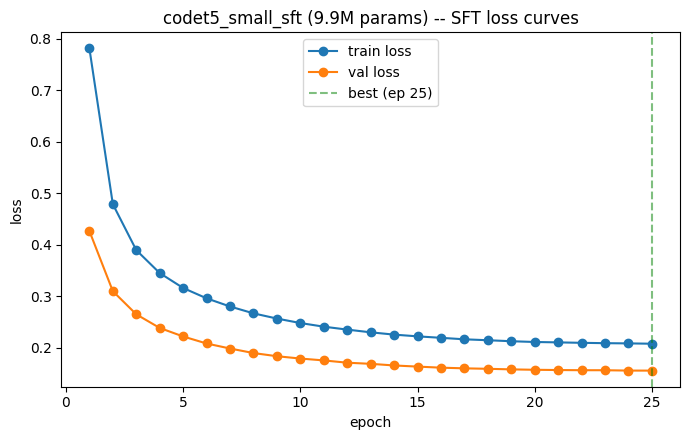

In [15]:
import matplotlib.pyplot as plt

history_path = SFT_CKPT_DIR / "training_history.json"
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
print(f"history saved -> {history_path}")

epochs_x   = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss   = [h["val_loss"] for h in history]
best_ep    = epochs_x[val_loss.index(min(val_loss))]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs_x, train_loss, marker="o", label="train loss")
ax.plot(epochs_x, val_loss, marker="o", label="val loss")
ax.axvline(x=best_ep, color="green", linestyle="--", alpha=0.5, label=f"best (ep {best_ep})")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title(f"{RUN_NAME} ({n_params/1e6:.1f}M params) -- SFT loss curves")
ax.legend()
plt.tight_layout()
plt.savefig(SFT_CKPT_DIR / "loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()